# Clustering and ML
This final notebook will apply an unsupervised K-Means clustering algorithm to segment Italian municipalities, build a Regression model to predict accidents, and export the final dataset for the Power BI dashboard storytelling.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df_raw = pd.read_csv("../data/2_final.csv",
    dtype={"REF_AREA": str, "PROVINCE": str},
    keep_default_na=False,
    na_values=[""]
)

print("Dataset loaded.")
df_raw.head()

Dataset loaded.


,REF_AREA,TIME_PERIOD,ACCIDENTS,DEATHS,INJURIES,NAME,PROVINCE,IS_PROVINCE_CAPITAL,IS_REGION_CAPITAL,AREA,POPULATION,ACCIDENTS_PER_1000_INH,DEATHS_PER_1000_INH,INJURIES_PER_1000_INH,ACCIDENTS_PER_KMQ,DEATHS_PER_KMQ,INJURIES_PER_KMQ,SEVERITY_INDEX
0,001001,2001,5,0,10,Agliè,TO,False,False,13.1463,2585,1.934236,0.0,3.868472,0.380335,0.0,0.760670,0.0
1,001001,2002,5,0,10,Agliè,TO,False,False,13.1463,2585,1.934236,0.0,3.868472,0.380335,0.0,0.760670,0.0
2,001001,2003,4,0,7,Agliè,TO,False,False,13.1463,2585,1.547389,0.0,2.707930,0.304268,0.0,0.532469,0.0
3,001001,2004,9,0,13,Agliè,TO,False,False,13.1463,2585,3.481625,0.0,5.029014,0.684603,0.0,0.988871,0.0
4,001001,2005,2,0,2,Agliè,TO,False,False,13.1463,2585,0.773694,0.0,0.773694,0.152134,0.0,0.152134,0.0


## STEP 1. K-Means Clustering
We will apply an unsupervised K-Means clustering algorithm to segment Italian municipalities into distinct risk profiles, taking into account both the scale of a city and its accident density.

The dataset will be filtered two ways:
- only data from 2024 onwards, since the poopulation data we have refers to 2024; and
- only municipalities with a population of at least 2.000, in order to avoid distorted accident rates due to small denominators.

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# Filter the last three years and only municipalities with at least 2.000 inhabitants
df = df_raw[(df_raw["TIME_PERIOD"] == 2024) & (df_raw["POPULATION"] >= 2000)].copy()

# Select features for clustering
cluster_features = ["ACCIDENTS_PER_1000_INH", "ACCIDENTS_PER_KMQ"]
df_cluster = df[["REF_AREA", "NAME", "PROVINCE", "POPULATION"] + cluster_features].dropna().copy()

# Scale the features
scaler = MinMaxScaler()
scaled_features = scaler.fit_transform(df_cluster[cluster_features])

# Add scaled features to dataframe
df_scaled = pd.DataFrame(scaled_features, columns=cluster_features)
df_scaled["REF_AREA"] = df_cluster["REF_AREA"].values
df_scaled["NAME"] = df_cluster["NAME"].values
df_scaled["PROVINCE"] = df_cluster["PROVINCE"].values
df_scaled["POPULATION"] = df_cluster["POPULATION"].values

# Check
df_scaled.head()

,ACCIDENTS_PER_1000_INH,ACCIDENTS_PER_KMQ,REF_AREA,NAME,PROVINCE,POPULATION
0,0.045164,0.003494,001001,Agliè,TO,2585
1,0.083648,0.007382,001002,Airasca,TO,3695
2,0.014875,0.002549,001006,Almese,TO,6297
3,0.074309,0.039330,001008,Alpignano,TO,16494
4,0.179790,0.034315,001013,Avigliana,TO,12139


We can now visualize a plot of the normalized features using the pairplot function to check if we can visually spot clusters.

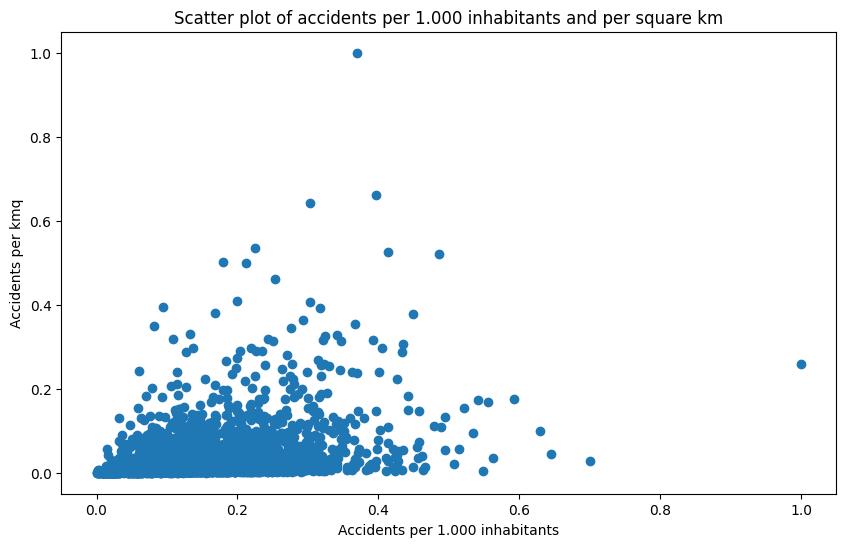

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.scatter(
    df_scaled["ACCIDENTS_PER_1000_INH"],
    df_scaled["ACCIDENTS_PER_KMQ"]
)

plt.title("Scatter plot of accidents per 1.000 inhabitants and per square km")
plt.xlabel("Accidents per 1.000 inhabitants")
plt.ylabel("Accidents per kmq")
plt.show()

By looking at this graph, it's pretty clear that clustering is not going to be particularly useful. Still, we can try to determine the optimal number of clusters with the WCSS method.

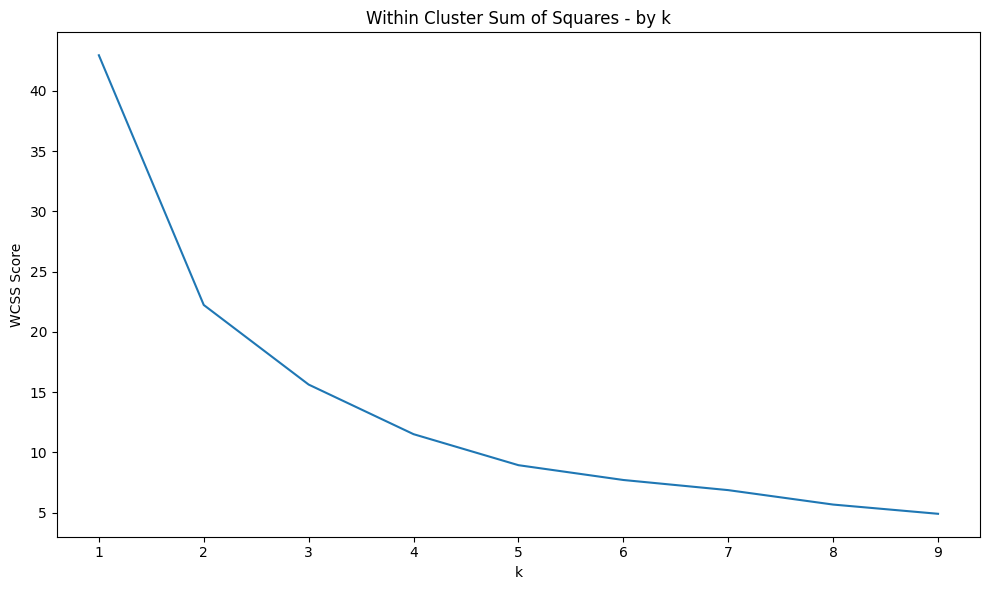

In [ ]:
k_values = list(range(1, 10))
wcss_list = []

for k in k_values:
    kmeans_wcss = KMeans(n_clusters=k, random_state=42)
    kmeans_wcss.fit(df_scaled[cluster_features])
    wcss_list.append(kmeans_wcss.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss_list)
plt.title("Within Cluster Sum of Squares - by k")
plt.xlabel("k")
plt.ylabel("WCSS Score")
plt.tight_layout()
plt.show()

By looking at the plotted k, we can locate roughly 3 lines, meaning that the optimal value of k might be 3.

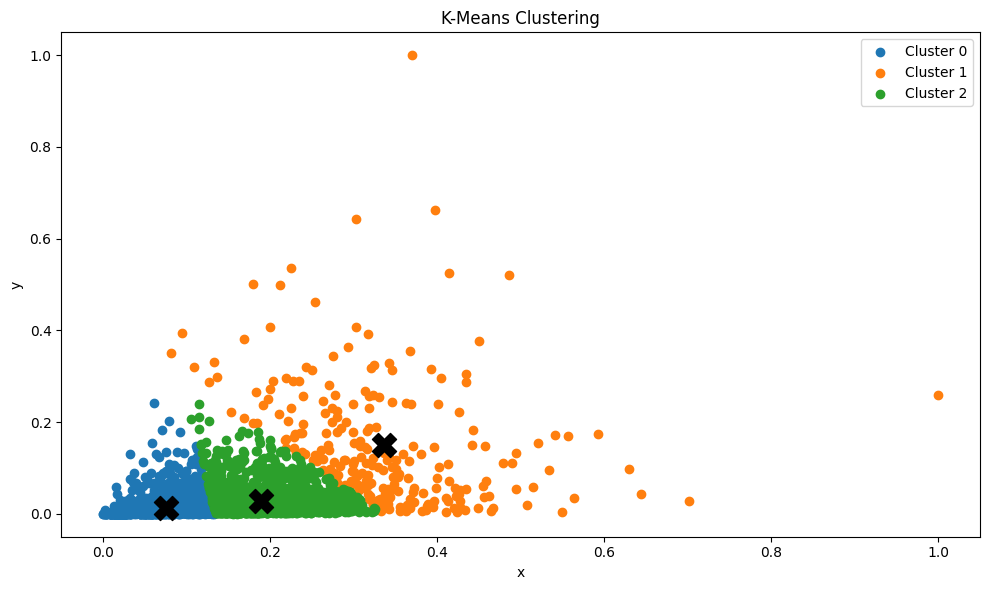

In [ ]:
# Instantiate and fit the KMeans model
kmeans_3 = KMeans(n_clusters=3, random_state=42)
kmeans_3.fit(df_scaled[cluster_features])

# Add the cluster labels to the DataFrame 
df_scaled["cluster"] = kmeans_3.labels_ 

# Plot the clusters and centroids 
centroids = kmeans_3.cluster_centers_ 
clusters = df_scaled.groupby("cluster")

plt.figure(figsize=(10, 6)) 
for cluster, data in clusters:
    plt.scatter(data["ACCIDENTS_PER_1000_INH"], data["ACCIDENTS_PER_KMQ"], marker="o", label=f'Cluster {cluster}')
    plt.scatter(centroids[cluster, 0], centroids[cluster, 1], marker="X", color="black", s=300)

plt.xlabel("x") 
plt.ylabel("y") 
plt.title("K-Means Clustering") 
plt.legend() 
plt.tight_layout() 
plt.show()

We can now add the clusters to our dataset, so that the clusters can be used for the Power BI dashboard.

In [ ]:
# Describe clusters
tag_map = {
    0: "Low Risk",
    1: "High Risk",
    2: "Medium Risk"
}

# Add column for cluster map
df_scaled["CLUSTER_TAG"] = df_scaled["cluster"].map(tag_map)

# Merge back into df, which contains 2024 data and cities with at least 2.000 inhabitants
final_export = df.merge(df_scaled[["NAME", "PROVINCE", "cluster", "CLUSTER_TAG"]], on=["NAME", "PROVINCE"], how='left')

# Export to CSV
final_export.to_csv("../data/3_clusters.csv", index=False)
print("Saved csv.")

Saved csv.


## STEP 2. Regression to predict 2030 accident rates
To forecast how many accidents, injuries and deaths will take place in 2030, we will be using a linear regression model based on the whole dataset except 2020 and 2021, in order to avoid skewing the prediction with the drop in accidents due to the pandemic-related restrictions.

For ease of use, the regression will be saved on a separate csv than the one where the K-Means output was stored.

In [ ]:
from sklearn.linear_model import LinearRegression

# Filter out COVID anomaly years (2020 and 2021) with tilde ~ notation
df_reg = df_raw[~df_raw["TIME_PERIOD"].isin([2020, 2021])].copy()

forecast_data = []

# Loop through each municipality to fit a multi-year trend line
for area, group in df_reg.groupby("REF_AREA"):
    # For newer municipalities (e.g. merges or suppressed ones), we might not have enough data;
    # linear regression needs two points, but we askfor 3 just to make sure
    if len(group) >= 3:
        X = group[["TIME_PERIOD"]].values
        
        # Observations to forecast
        y_acc = group["ACCIDENTS"].values
        y_inj = group["INJURIES"].values
        y_dea = group["DEATHS"].values
        
        # Regression for accidents
        model_acc = LinearRegression()
        model_acc.fit(X, y_acc)
        pred_acc = max(0, model_acc.predict([[2030]])[0])
        
        # Regression for injuries
        model_inj = LinearRegression()
        model_inj.fit(X, y_inj)
        pred_inj = max(0, model_inj.predict([[2030]])[0])
        
        # Regression for deaths
        model_dea = LinearRegression()
        model_dea.fit(X, y_dea)
        pred_dea = max(0, model_dea.predict([[2030]])[0])

        # Add results to the empty variable
        forecast_data.append({
            "REF_AREA": area,
            "PREDICTED_ACCIDENTS_2030": pred_acc,
            "PREDICTED_INJURIES_2030": pred_inj,
            "PREDICTED_DEATHS_2030": pred_dea
        })

# Convert results to a DataFrame
df_forecast = pd.DataFrame(forecast_data)

Now that we predicted accidents, injuries and deaths in 2030, we can merge the columns with other columns of the original dataframe.

In [ ]:
# Merge the forecast with original info
df_final = df_forecast.merge(
    df_raw[['REF_AREA', 'NAME', 'PROVINCE', 'POPULATION', 'AREA']].drop_duplicates(subset=['REF_AREA']), 
    on="REF_AREA", 
    how="left"
)

# Reorder columns
df_final = df_final[['REF_AREA', 'NAME', 'PROVINCE', 'POPULATION', 'AREA', 'PREDICTED_ACCIDENTS_2030', 'PREDICTED_INJURIES_2030', 'PREDICTED_DEATHS_2030']]

# Check
display(df_final.sort_values(by="REF_AREA").head(10))

,REF_AREA,NAME,PROVINCE,POPULATION,AREA,PREDICTED_ACCIDENTS_2030,PREDICTED_INJURIES_2030,PREDICTED_DEATHS_2030
0,001001,Agliè,TO,2585,13.1463,1.558761,3.187019,0.248098
1,001002,Airasca,TO,3695,15.7393,0.000000,0.000000,0.252059
2,001003,Ala di Stura,TO,463,46.3316,0.874916,1.127290,0.000000
3,001004,Albiano d'Ivrea,TO,1624,11.7397,2.365441,5.781204,0.000000
4,001006,Almese,TO,6297,17.8741,3.753972,4.350407,0.004276
5,001007,Alpette,TO,248,5.6311,0.326655,1.356067,0.000000
6,001008,Alpignano,TO,16494,11.9193,15.487645,17.797903,0.000000
7,001009,Andezeno,TO,1995,7.4859,1.124139,2.357834,0.000000
8,001010,Andrate,TO,466,9.3090,0.000000,0.000000,0.000000
9,001011,Angrogna,TO,804,38.8781,0.000000,0.000000,0.000000


We can now save the results to a new csv.

In [ ]:
df_forecast.to_csv("../data/4_regression.csv", index=False)
print("Saved csv.")

Saved csv.
